In [ ]:
import pandas as pd
import numpy as np

np.random.seed(42)

dates = pd.date_range(start="2024-01-01", end="2025-12-31", freq="D")

departments = [
    "General Medicine",
    "Pediatrics",
    "Cardiology",
    "Orthopedics",
    "ENT"
]

data = []

for date in dates:
    month = date.month

    if month in [3, 4, 5]:
        temperature = np.random.normal(32, 3)
    elif month in [6, 7, 8, 9]:
        temperature = np.random.normal(28, 3)
    elif month in [10, 11, 12]:
        temperature = np.random.normal(26, 3)
    else:
        temperature = np.random.normal(25, 3)


    if month in [6, 7, 8, 9, 10, 11]:
        rainfall = np.random.exponential(8)
    else:
        rainfall = np.random.exponential(2)


    humidity = np.clip(
        55 + rainfall * 2 + np.random.normal(0, 8),
        30,
        95
    )


    air_quality = np.clip(
        80 + np.random.normal(0, 20),
        30,
        180
    )

    for department in departments:

        department_base = {
            "General Medicine": 70,
            "Pediatrics": 55,
            "Cardiology": 35,
            "Orthopedics": 45,
            "ENT": 40
        }

        base = department_base[department]

        weather_effect = (
            -0.8 * abs(temperature - 27)
            + 0.4 * rainfall
            + 0.15 * humidity
            + 0.08 * air_quality
        )

        outpatient = max(
            5,
            int(base + weather_effect + np.random.normal(0, 8))
        )

        emergency = max(
            2,
            int(
                base * 0.25
                + 0.3 * abs(temperature - 27)
                + 0.5 * rainfall
                + 0.12 * air_quality
                + np.random.normal(0, 4)
            )
        )

        data.append([
            date,
            department,
            outpatient,
            emergency,
            round(temperature, 2),
            round(rainfall, 2),
            round(humidity, 2),
            round(air_quality, 2)
        ])



df = pd.DataFrame(
    data,
    columns=[
        "Date",
        "Department",
        "Outpatient_Count",
        "Emergency_Count",
        "Temperature",
        "Rainfall",
        "Humidity",
        "Air_Quality"
    ]
)

print("Dataset created successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset created successfully!
Shape: (3655, 8)


,Date,Department,Outpatient_Count,Emergency_Count,Temperature,Rainfall,Humidity,Air_Quality
0,2024-01-01,General Medicine,86,27,26.49,2.63,59.16,57.76
1,2024-01-01,Pediatrics,77,19,26.49,2.63,59.16,57.76
2,2024-01-01,Cardiology,44,14,26.49,2.63,59.16,57.76
3,2024-01-01,Orthopedics,51,9,26.49,2.63,59.16,57.76
4,2024-01-01,ENT,61,21,26.49,2.63,59.16,57.76


In [ ]:

print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Shape:
(3655, 8)

Column Names:
['Date', 'Department', 'Outpatient_Count', 'Emergency_Count', 'Temperature', 'Rainfall', 'Humidity', 'Air_Quality']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3655 entries, 0 to 3654
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Date              3655 non-null   datetime64[ns]
 1   Department        3655 non-null   object        
 2   Outpatient_Count  3655 non-null   int64         
 3   Emergency_Count   3655 non-null   int64         
 4   Temperature       3655 non-null   float64       
 5   Rainfall          3655 non-null   float64       
 6   Humidity          3655 non-null   float64       
 7   Air_Quality       3655 non-null   float64       
dtypes: datetime64[ns](1), float64(4), int64(2), object(1)
memory usage: 228.6+ KB

Missing Values:
Date                0
Department          0
Outpatient_Count    0
Emergency_

In [ ]:

df["Total_Patient_Arrivals"] = (
    df["Outpatient_Count"] + df["Emergency_Count"]
)

display(df.head())

,Date,Department,Outpatient_Count,Emergency_Count,Temperature,Rainfall,Humidity,Air_Quality,Total_Patient_Arrivals
0,2024-01-01,General Medicine,86,27,26.49,2.63,59.16,57.76,113
1,2024-01-01,Pediatrics,77,19,26.49,2.63,59.16,57.76,96
2,2024-01-01,Cardiology,44,14,26.49,2.63,59.16,57.76,58
3,2024-01-01,Orthopedics,51,9,26.49,2.63,59.16,57.76,60
4,2024-01-01,ENT,61,21,26.49,2.63,59.16,57.76,82


In [ ]:

df.describe()

,Date,Outpatient_Count,Emergency_Count,Temperature,Rainfall,Humidity,Air_Quality,Total_Patient_Arrivals
count,3655,3655.000000,3655.000000,3655.000000,3655.000000,3655.000000,3655.000000,3655.000000
mean,2024-12-30 23:59:59.999999744,63.951573,24.895486,27.767729,4.919699,64.120985,80.659466,88.847059
min,2024-01-01 00:00:00,19.000000,4.000000,17.530000,0.010000,32.590000,30.000000,36.000000
25%,2024-07-01 00:00:00,53.000000,20.000000,24.830000,0.980000,55.840000,67.830000,74.000000
50%,2024-12-31 00:00:00,62.000000,24.000000,27.480000,2.510000,62.080000,81.220000,86.000000
75%,2025-07-02 00:00:00,75.000000,29.000000,30.660000,6.080000,70.350000,94.520000,103.000000
max,2025-12-31 00:00:00,117.000000,60.000000,40.190000,52.640000,95.000000,131.790000,165.000000
std,NaN,15.485117,6.402015,3.961949,6.539298,12.639255,19.393394,19.694419


In [ ]:

department_summary = (
    df.groupby("Department")["Total_Patient_Arrivals"]
      .agg(["mean", "min", "max", "std"])
      .round(2)
)

display(department_summary)

,mean,min,max,std
Department,,,,
Cardiology,71.44,36,130,12.39
ENT,77.18,47,129,11.61
General Medicine,114.80,85,165,12.07
Orthopedics,84.05,50,136,12.37
Pediatrics,96.76,62,157,12.42


In [ ]:

df["Date"] = pd.to_datetime(df["Date"])


df["Month"] = df["Date"].dt.month


df["Month_Name"] = df["Date"].dt.month_name()


display(df[["Date", "Month", "Month_Name"]].head())

,Date,Month,Month_Name
0,2024-01-01,1,January
1,2024-01-01,1,January
2,2024-01-01,1,January
3,2024-01-01,1,January
4,2024-01-01,1,January


In [ ]:

monthly_patients = (
    df.groupby(["Month", "Month_Name"])["Total_Patient_Arrivals"]
      .mean()
      .reset_index()
      .sort_values("Month")
)

display(monthly_patients)

,Month,Month_Name,Total_Patient_Arrivals
0,1,January,86.083871
1,2,February,85.831579
2,3,March,84.941935
3,4,April,84.443333
4,5,May,84.338710
5,6,June,92.966667
6,7,July,92.722581
7,8,August,91.574194
8,9,September,93.356667
9,10,October,93.141935


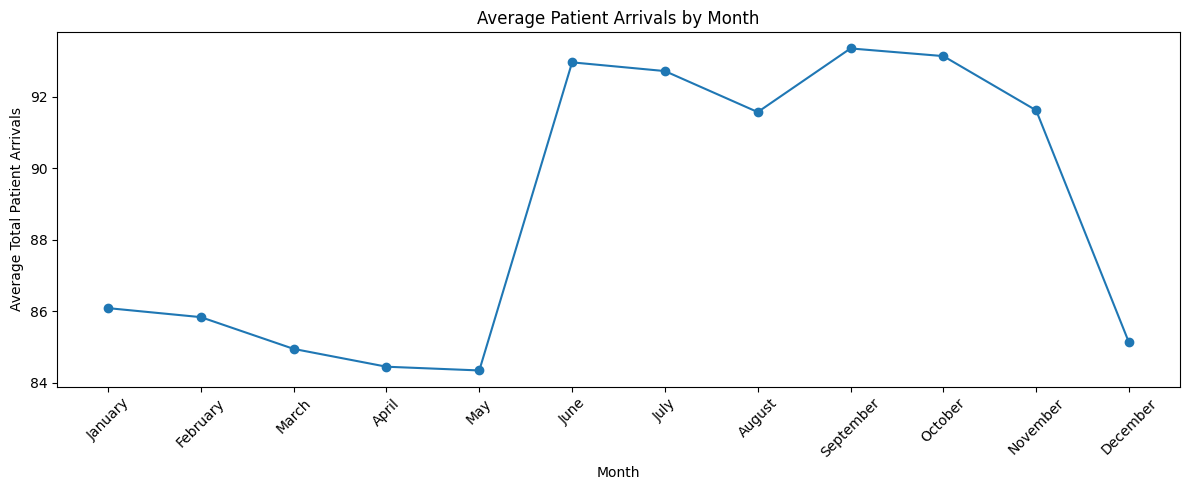

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_patients["Month_Name"],
    monthly_patients["Total_Patient_Arrivals"],
    marker="o"
)

plt.title("Average Patient Arrivals by Month")
plt.xlabel("Month")
plt.ylabel("Average Total Patient Arrivals")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:

df["Rainfall_Category"] = pd.cut(
    df["Rainfall"],
    bins=[-0.1, 2, 10, float("inf")],
    labels=["Low Rainfall", "Moderate Rainfall", "Heavy Rainfall"]
)

print(df["Rainfall_Category"].value_counts())

Rainfall_Category
Low Rainfall         1615
Moderate Rainfall    1555
Heavy Rainfall        485
Name: count, dtype: int64


In [ ]:

rainfall_summary = (
    df.groupby("Rainfall_Category", observed=True)["Total_Patient_Arrivals"]
      .agg(["mean", "min", "max", "std"])
      .round(2)
)

display(rainfall_summary)

,mean,min,max,std
Rainfall_Category,,,,
Low Rainfall,84.59,36,141,18.55
Moderate Rainfall,88.56,42,143,18.39
Heavy Rainfall,103.97,49,165,20.12


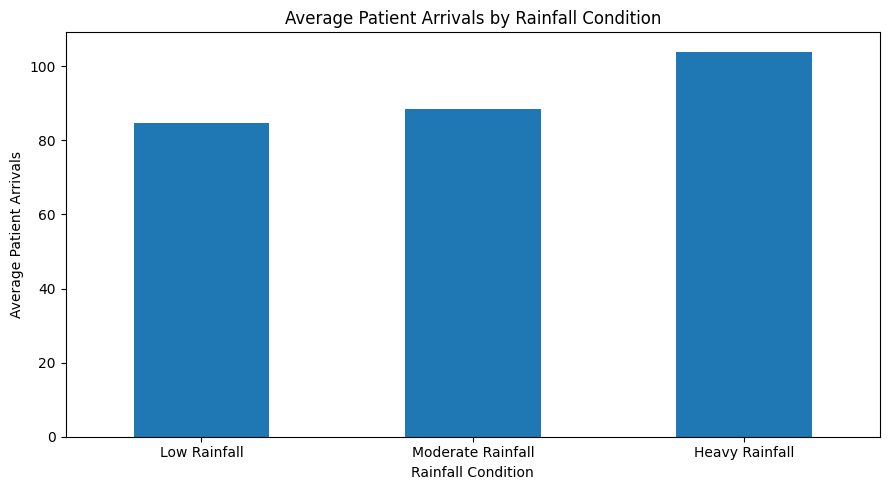

In [ ]:
plt.figure(figsize=(9, 5))

rainfall_summary["mean"].plot(kind="bar")

plt.title("Average Patient Arrivals by Rainfall Condition")
plt.xlabel("Rainfall Condition")
plt.ylabel("Average Patient Arrivals")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [ ]:

weather_columns = [
    "Temperature",
    "Rainfall",
    "Humidity",
    "Air_Quality"
]


department_correlations = {}

for department in df["Department"].unique():

    dept_data = df[df["Department"] == department]

    correlations = dept_data[
        weather_columns + ["Total_Patient_Arrivals"]
    ].corr()["Total_Patient_Arrivals"]

    department_correlations[department] = correlations.drop(
        "Total_Patient_Arrivals"
    )


correlation_df = pd.DataFrame(department_correlations).T

display(correlation_df.round(3))

,Temperature,Rainfall,Humidity,Air_Quality
General Medicine,-0.070,0.549,0.466,0.308
Pediatrics,-0.090,0.608,0.495,0.265
Cardiology,-0.105,0.569,0.480,0.287
Orthopedics,-0.065,0.601,0.475,0.297
ENT,-0.092,0.608,0.520,0.240


In [ ]:
department_effects = pd.DataFrame({
    "Strongest_Weather_Factor": correlation_df.abs().idxmax(axis=1)
})

department_effects["Correlation"] = [
    correlation_df.loc[dept, factor]
    for dept, factor in department_effects["Strongest_Weather_Factor"].items()
]

display(department_effects.round(3))

,Strongest_Weather_Factor,Correlation
General Medicine,Rainfall,0.549
Pediatrics,Rainfall,0.608
Cardiology,Rainfall,0.569
Orthopedics,Rainfall,0.601
ENT,Rainfall,0.608


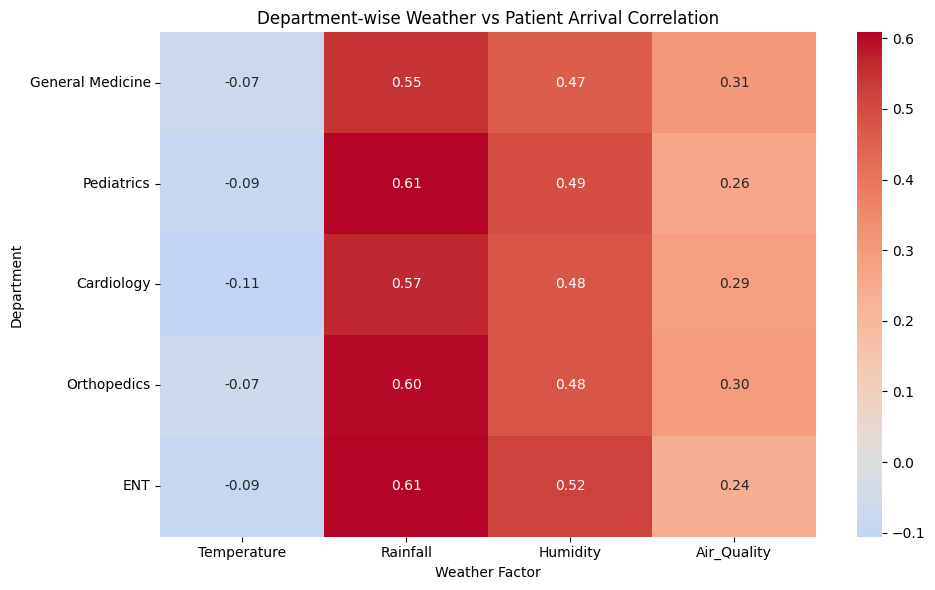

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation_df,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Department-wise Weather vs Patient Arrival Correlation")
plt.xlabel("Weather Factor")
plt.ylabel("Department")

plt.tight_layout()
plt.show()

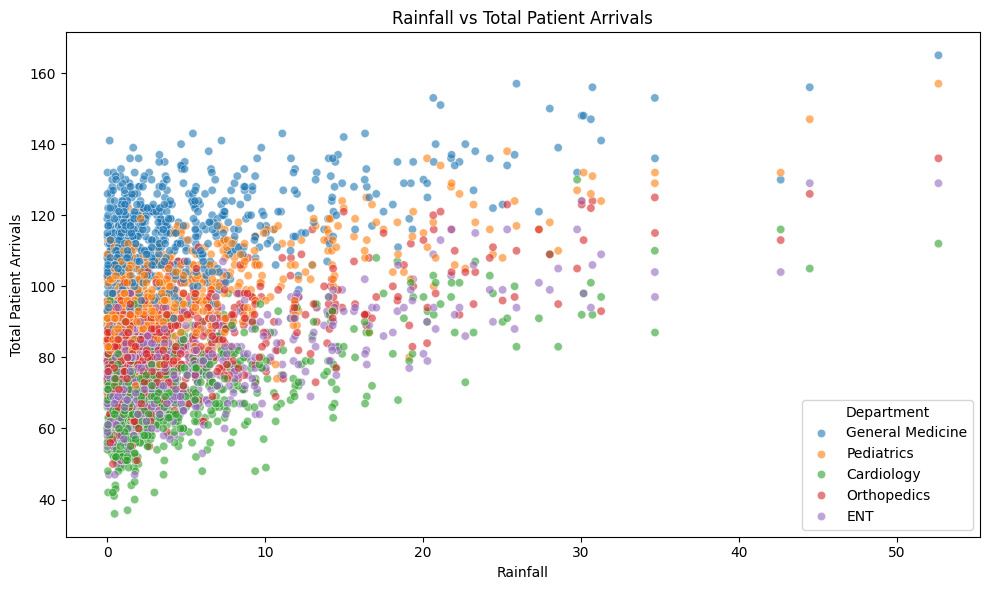

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Rainfall",
    y="Total_Patient_Arrivals",
    hue="Department",
    alpha=0.6
)

plt.title("Rainfall vs Total Patient Arrivals")
plt.xlabel("Rainfall")
plt.ylabel("Total Patient Arrivals")

plt.tight_layout()
plt.show()

In [ ]:


weather_columns = [
    "Temperature",
    "Rainfall",
    "Humidity",
    "Air_Quality"
]

overall_correlation = (
    df[weather_columns + ["Total_Patient_Arrivals"]]
    .corr()["Total_Patient_Arrivals"]
    .drop("Total_Patient_Arrivals")
    .sort_values(ascending=False)
)

print("Correlation with Total Patient Arrivals:")
display(overall_correlation.round(3))

Correlation with Total Patient Arrivals:


,Total_Patient_Arrivals
Rainfall,0.363
Humidity,0.301
Air_Quality,0.173
Temperature,-0.052


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression


X = df[
    [
        "Temperature",
        "Rainfall",
        "Humidity",
        "Air_Quality"
    ]
]


y = df["Total_Patient_Arrivals"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (3655, 4)
y shape: (3655,)


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 2924
Testing samples: 731


In [ ]:

model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np


y_pred = model.predict(X_test)


mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Linear Regression Model Evaluation")
print("-----------------------------------")
print("MAE  :", round(mae, 2))
print("MSE  :", round(mse, 2))
print("RMSE :", round(rmse, 2))
print("R²   :", round(r2, 3))

Linear Regression Model Evaluation
-----------------------------------
MAE  : 14.71
MSE  : 312.0
RMSE : 17.66
R²   : 0.194


In [ ]:

coefficients = pd.DataFrame({
    "Weather_Factor": X.columns,
    "Coefficient": model.coef_
})

display(coefficients.round(3))

,Weather_Factor,Coefficient
0,Temperature,-0.131
1,Rainfall,0.963
2,Humidity,0.105
3,Air_Quality,0.184


In [ ]:


print("===== FINAL SUMMARY =====")

print("\n1. Total records:", len(df))

print("\n2. Average total patient arrivals:",
      round(df["Total_Patient_Arrivals"].mean(), 2))

print("\n3. Average outpatient count:",
      round(df["Outpatient_Count"].mean(), 2))

print("\n4. Average emergency count:",
      round(df["Emergency_Count"].mean(), 2))

print("\n5. Month with highest average arrivals:")
highest_month = monthly_patients.loc[
    monthly_patients["Total_Patient_Arrivals"].idxmax()
]
print(
    highest_month["Month_Name"],
    "->",
    round(highest_month["Total_Patient_Arrivals"], 2)
)

print("\n6. Rainfall condition with highest average arrivals:")
highest_rainfall = rainfall_summary["mean"].idxmax()
print(
    highest_rainfall,
    "->",
    round(rainfall_summary.loc[highest_rainfall, "mean"], 2)
)

print("\n7. Department with highest average arrivals:")
dept_avg = df.groupby("Department")["Total_Patient_Arrivals"].mean()
print(
    dept_avg.idxmax(),
    "->",
    round(dept_avg.max(), 2)
)

print("\n8. Strongest overall weather correlation:")
strongest_weather = overall_correlation.abs().idxmax()
print(
    strongest_weather,
    "->",
    round(overall_correlation[strongest_weather], 3)
)

print("\n9. Linear Regression R²:", round(r2, 3))
print("10. Linear Regression MAE:", round(mae, 2))
print("11. Linear Regression RMSE:", round(rmse, 2))

===== FINAL SUMMARY =====

1. Total records: 3655

2. Average total patient arrivals: 88.85

3. Average outpatient count: 63.95

4. Average emergency count: 24.9

5. Month with highest average arrivals:
September -> 93.36

6. Rainfall condition with highest average arrivals:
Heavy Rainfall -> 103.97

7. Department with highest average arrivals:
General Medicine -> 114.8

8. Strongest overall weather correlation:
Rainfall -> 0.363

9. Linear Regression R²: 0.194
10. Linear Regression MAE: 14.71
11. Linear Regression RMSE: 17.66


## Key Insights

1. The dataset contains 3,655 records covering two years of daily hospital observations across five departments.

2. The average total patient arrival was 88.85 patients per department-day, consisting of an average of 63.95 outpatient visits and 24.90 emergency visits.

3. September recorded the highest average patient arrivals at 93.36, indicating a noticeable seasonal variation in patient volume.

4. Heavy rainfall conditions had the highest average patient arrivals at 103.97, compared with the other rainfall categories.

5. General Medicine had the highest average patient arrivals among the five departments, with an average of 114.8 patients per department-day.

6. Rainfall showed the strongest overall correlation with patient arrivals, with a correlation coefficient of 0.363. This indicates a moderate positive relationship in the simulated dataset.

7. The Linear Regression model achieved an R² of 0.194, meaning the four weather variables together explained about 19.4% of the variation in patient arrivals. The MAE was 14.71 and RMSE was 17.66.

## Practical Action Plan

1. Monitor rainfall forecasts and prepare additional hospital resources during periods of heavy rainfall.

2. General Medicine should be monitored closely because it recorded the highest average patient arrivals.

3. Hospital management can use seasonal patient-arrival patterns to plan staffing and resources during months with higher expected demand.

4. Emergency and outpatient departments can maintain flexible staffing during periods of unusual weather conditions.

5. Weather information can be included in hospital demand-monitoring dashboards to identify possible increases in patient arrivals.

6. Since weather variables explained only 19.4% of the variation in patient arrivals, future analysis should include additional factors such as day of week, holidays, disease outbreaks, appointments, and special events.

7. The results should be treated as evidence of association rather than proof that weather directly causes changes in patient arrivals.